# Solar Filament Image Segmentation — Version 5 (v5)
### High-Resolution Tiling, Pretrained ImageNet Encoder, Recall-Biased BCE-Tversky Loss & Watershed Separation

This notebook adapts and expands [`filament_pipeline_v5.py`](file:///c:/Users/atiks/Desktop/filament-segmentation-2026/v5/filament_pipeline_v5.py) into a complete, interactive, end-to-end pipeline.

**Key Architectural Advancements in v5:**
1. **High-Resolution Tiling ($2048\times 2048 \rightarrow 512\times 512$ Tiles with $25\%$ Stride Overlap)**: Prevents thin solar filaments and fine barbs from being crushed by whole-disk downsampling.
2. **Real MAGFiLO Schema Adaptation**: Seamlessly parses COCO `images` and `annotations` (`file_name`, polygon coords, image dimensions).
3. **Pretrained ImageNet Encoder (ResNet34 / SMP)**: Leverages rich transfer learning features rather than training from scratch.
4. **Recall-Biased BCE-Tversky Loss ($\alpha=0.3, \beta=0.7$)**: Strongly penalizes False Negatives to fix the low Recognition Quality ($RQ$) / missed filament problem.
5. **Watershed Instance Separation**: Uses Euclidean Distance Transform (EDT) + marker-based watershed to cleanly separate touching filaments without fragmenting single bodies.
6. **Configurable Subsetting & Smoke-Test Switch**: Allows running a quick subset test before committing to full high-res training.

## 1. Environment Verification & Dependencies

Verifies CUDA GPU acceleration, PyTorch AMP support, and imports `segmentation_models_pytorch`.

In [1]:
import os
import sys
import json
import random
from pathlib import Path
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split, Subset
import torchvision.transforms.functional as TF
from torch.amp import autocast, GradScaler

import segmentation_models_pytorch as smp
from scipy import ndimage as ndi
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from skimage.measure import label, regionprops

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)
print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)} | VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"SMP Version: {smp.__version__}")


c:\Users\HARSHA VARDHAN\OneDrive\Documents\CODING\DEEP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128
CUDA Available: True
Device: NVIDIA GeForce RTX 4050 Laptop GPU | VRAM: 6.44 GB
SMP Version: 0.5.0


## 2. Configuration & Hyperparameters

- **`FULL_RES`**: Resolution for whole-disk image normalization ($2048\times 2048$).
- **`TILE_SIZE` & `STRIDE`**: $512\times 512$ with stride $384$ ($25\%$ overlap to avoid boundary cuts).
- **`TVERSKY_ALPHA` & `TVERSKY_BETA`**: $\alpha=0.3, \beta=0.7$ (recall-biased).
- **`DRY_RUN_SUBSET`**: If `True`, trains on a smaller image subset (e.g. 50 images) for rapid verification.

In [2]:
class Config:
    # Dynamic directory resolution
    BASE_DIR = Path(r"C:\Users\HARSHA VARDHAN\OneDrive\Documents\CODING\DEEP\MAGFiLO_1.0_Kaggle_2026")
    DATA_DIR = BASE_DIR
    TRAIN_JSON = DATA_DIR / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    TRAIN_IMG_DIR = DATA_DIR / "train" / "train_images"
    TEST_IMG_DIR = DATA_DIR / "test" / "test_images"

    # High-Resolution Tiling Grid
    FULL_RES = 2048
    TILE_SIZE = 512
    STRIDE = 384     # 25% overlap (512 - 384 = 128 px overlap)
    FILTER_EMPTY_TILES = True  # Keep only tiles with filament pixels or a small background fraction
    BG_TILE_KEEP_RATIO = 0.05  # Fraction of purely empty background tiles to retain for negative training
    
    # Model & Loss Configuration
    ENCODER_NAME = "resnet34"
    ENCODER_WEIGHTS = "imagenet"
    TVERSKY_ALPHA = 0.3    # False Positive Penalty
    TVERSKY_BETA = 0.7     # False Negative Penalty (Recall bias)
    BCE_WEIGHT = 0.5       # Balance between BCE and Tversky loss
    
    # Training Parameters
    NUM_EPOCHS = 20
    BATCH_SIZE = 8
    LEARNING_RATE = 1e-4
    WEIGHT_DECAY = 1e-4
    VAL_SPLIT = 0.15
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Smoke-test / Subsetting Mode (Set to True for fast check)
    DRY_RUN_SUBSET = False
    SUBSET_IMAGE_COUNT = 40
    
    # Post-processing & Metric Evaluation
    PROB_THRESHOLD = 0.45
    MIN_AREA_THRESHOLD = 500
    
    # Model Save & Submission Files
    MODEL_SAVE_PATH = "best_filament_unet_v5.pt"
    SUBMISSION_PATH = "submission_v5.csv"

config = Config()
print(f"Data Directory: {config.DATA_DIR.resolve()}")
print(f"Train JSON Exists: {config.TRAIN_JSON.exists()}")
train_imgs_all = (list(config.TRAIN_IMG_DIR.glob('*.png')) +
                  list(config.TRAIN_IMG_DIR.glob('*.jpeg')) +
                  list(config.TRAIN_IMG_DIR.glob('*.jpg')))
print(f"Train Images: {len(train_imgs_all)}")
test_imgs_all = (list(config.TEST_IMG_DIR.glob('*.png')) +
                 list(config.TEST_IMG_DIR.glob('*.jpeg')) +
                 list(config.TEST_IMG_DIR.glob('*.jpg')))
print(f"Test Images:  {len(test_imgs_all)}")


Data Directory: C:\Users\HARSHA VARDHAN\OneDrive\Documents\CODING\DEEP\MAGFiLO_1.0_Kaggle_2026
Train JSON Exists: True
Train Images: 707
Test Images:  180


## 3. High-Resolution Tiling Dataset (Adapted to Real MAGFiLO Schema)

### Schema Adaptation Details:
1. **`images`**: List of dictionaries containing `id`, `file_name` (e.g. `20110101_000000.png`), `width`, and `height`.
2. **`annotations`**: List of dictionaries containing `image_id`, and `segmentation` polygon coordinates `[[x1, y1, x2, y2, ...]]`.
3. **Polygon Scaling**: Coordinates are mapped from $(W_{\text{orig}}, H_{\text{orig}})$ to $(2048, 2048)$ before rasterization.
4. **Tile Grid**: Covers the $2048\times 2048$ canvas with $512\times 512$ tiles at stride $384$, guaranteeing full boundary coverage.
5. **LRU Image Cache**: Uses `@lru_cache(maxsize=16)` so adjacent tiles from the same solar disk do not re-read from disk.

In [3]:
from pathlib import Path
import json
import gc

TRAIN_JSON = Path(r"C:\Users\HARSHA VARDHAN\OneDrive\Documents\CODING\DEEP\MAGFiLO_1.0_Kaggle_2026\train\MAGFiLO_1.0_Annotations_kaggle2026_train.json")

with open(TRAIN_JSON, 'r') as f:
    coco_data = json.load(f)

images_dict = {img['id']: img for img in coco_data['images']}

annotations_by_image = {}

for ann in coco_data['annotations']:
    img_id = ann['image_id']
    if img_id not in annotations_by_image:
        annotations_by_image[img_id] = []
    annotations_by_image[img_id].append(ann)

print(f"Loaded {len(images_dict)} images and {len(coco_data['annotations'])} annotations.")

class FilamentTileDataset(Dataset):
    def __init__(self, image_ids, images_dict, annotations_by_image, image_dir,
                 full_res=2048, tile_size=512, stride=384, filter_empty=True, bg_keep_ratio=0.05, is_train=True):
        self.image_ids = list(image_ids)
        self.images_dict = images_dict
        self.annotations_by_image = annotations_by_image
        self.image_dir = Path(image_dir)
        self.full_res = full_res
        self.tile_size = tile_size
        self.stride = stride
        self.is_train = is_train
        
        # Manual LRU cache (avoids memory leaks from @lru_cache retaining self)
        self._cache = {}
        self._cache_order = []
        self._cache_maxsize = 16
        
        self.tile_coords = self._build_tile_grid(full_res, tile_size, stride)
        
        # Build active index list
        raw_index = [
            (img_i, tile_i)
            for img_i in range(len(self.image_ids))
            for tile_i in range(len(self.tile_coords))
        ]
        
        if filter_empty and is_train:
            print(f"Filtering empty background tiles (Total raw candidate tiles: {len(raw_index)})...")
            filtered_index = []
            for img_i, tile_i in raw_index:
                img_id = self.image_ids[img_i]
                x, y = self.tile_coords[tile_i]
                ts = self.tile_size

                # Per-tile pixel check: load cached full mask and crop this specific tile
                _, full_mask = self._load_full_image_and_mask(img_id)
                mask_tile = np.array(full_mask.crop((x, y, x + ts, y + ts)))
                has_filament_pixels = mask_tile.sum() > 0

                if has_filament_pixels:
                    filtered_index.append((img_i, tile_i))
                elif random.random() < bg_keep_ratio:
                    # Randomly retain a small fraction of empty background tiles
                    filtered_index.append((img_i, tile_i))
            self.index = filtered_index
            # Clear cache after filtering to free memory before training
            self._cache.clear()
            self._cache_order.clear()
            gc.collect()
            print(f"Retained {len(self.index)} active tiles for training "
                  f"(from {len(raw_index)} raw candidates).")
        else:
            self.index = raw_index

    @staticmethod
    def _build_tile_grid(full_res, tile_size, stride):
        coords = set()
        for y in range(0, full_res - tile_size + 1, stride):
            for x in range(0, full_res - tile_size + 1, stride):
                coords.add((x, y))
        last = full_res - tile_size
        for y in range(0, full_res - tile_size + 1, stride):
            coords.add((last, y))
        for x in range(0, full_res - tile_size + 1, stride):
            coords.add((x, last))
        coords.add((last, last))
        return sorted(coords)

    def _load_full_image_and_mask(self, image_id):
        """Load image and mask with manual LRU cache to avoid memory leaks."""
        if image_id in self._cache:
            # Move to end (most recently used)
            self._cache_order.remove(image_id)
            self._cache_order.append(image_id)
            return self._cache[image_id]
        
        # Evict oldest entry if cache is full
        while len(self._cache_order) >= self._cache_maxsize:
            evicted_id = self._cache_order.pop(0)
            del self._cache[evicted_id]
        
        img_info = self.images_dict[image_id]
        img_path = self.image_dir / img_info['file_name']
        
        image = Image.open(img_path).convert("L")
        orig_w, orig_h = image.size
        image = image.resize((self.full_res, self.full_res), Image.BILINEAR)
        
        scale_x = self.full_res / orig_w
        scale_y = self.full_res / orig_h
        
        mask = Image.new("L", (self.full_res, self.full_res), 0)
        draw = ImageDraw.Draw(mask)
        
        anns = self.annotations_by_image.get(image_id, [])
        for ann in anns:
            for poly in ann.get('segmentation', []):
                scaled = [(poly[i] * scale_x, poly[i+1] * scale_y) for i in range(0, len(poly), 2)]
                if len(scaled) >= 3:
                    draw.polygon(scaled, fill=1)
        
        result = (image, mask)
        self._cache[image_id] = result
        self._cache_order.append(image_id)
        return result

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        img_idx, tile_idx = self.index[idx]
        image_id = self.image_ids[img_idx]
        image, mask = self._load_full_image_and_mask(image_id)

        x, y = self.tile_coords[tile_idx]
        ts = self.tile_size
        img_tile = image.crop((x, y, x + ts, y + ts))
        mask_tile = mask.crop((x, y, x + ts, y + ts))
        
        # Data Augmentations (Train Mode)
        if self.is_train:
            if random.random() > 0.5:
                img_tile = TF.hflip(img_tile)
                mask_tile = TF.hflip(mask_tile)
            if random.random() > 0.5:
                img_tile = TF.vflip(img_tile)
                mask_tile = TF.vflip(mask_tile)
            rot = random.choice([0, 90, 180, 270])
            if rot > 0:
                img_tile = TF.rotate(img_tile, rot)
                mask_tile = TF.rotate(mask_tile, rot)
                
        # Repeat single-channel grayscale to 3 channels for ImageNet Pretrained Encoder
        img_t = TF.to_tensor(img_tile).repeat(3, 1, 1)
        mask_t = torch.from_numpy(np.array(mask_tile)).float().unsqueeze(0)
        return img_t, mask_t


Loaded 1154 images and 8199 annotations.


In [4]:
all_img_ids = list(images_dict.keys())
random.seed(42)
random.shuffle(all_img_ids)

# Optional Subsetting for Fast Dry-Run
if config.DRY_RUN_SUBSET:
    print(f"*** DRY RUN ENABLED: Subsetting to {config.SUBSET_IMAGE_COUNT} images ***")
    all_img_ids = all_img_ids[:config.SUBSET_IMAGE_COUNT]

val_count = int(len(all_img_ids) * config.VAL_SPLIT)
val_img_ids = all_img_ids[:val_count]
train_img_ids = all_img_ids[val_count:]

train_dataset = FilamentTileDataset(
    train_img_ids, images_dict, annotations_by_image, config.TRAIN_IMG_DIR,
    full_res=config.FULL_RES, tile_size=config.TILE_SIZE, stride=config.STRIDE,
    filter_empty=config.FILTER_EMPTY_TILES, bg_keep_ratio=config.BG_TILE_KEEP_RATIO, is_train=True
)

val_dataset = FilamentTileDataset(
    val_img_ids, images_dict, annotations_by_image, config.TRAIN_IMG_DIR,
    full_res=config.FULL_RES, tile_size=config.TILE_SIZE, stride=config.STRIDE,
    filter_empty=False, is_train=False
)

train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"Train Tiles: {len(train_dataset)} | Val Tiles: {len(val_dataset)}")
print(f"Train Batches: {len(train_loader)} | Val Batches: {len(val_loader)}")


Filtering empty background tiles (Total raw candidate tiles: 24525)...
Retained 10855 active tiles for training (from 24525 raw candidates).
Train Tiles: 10855 | Val Tiles: 4325
Train Batches: 1357 | Val Batches: 541


## 4. Visual Inspection (EDA): High-Resolution Cropped Tiles & Masks

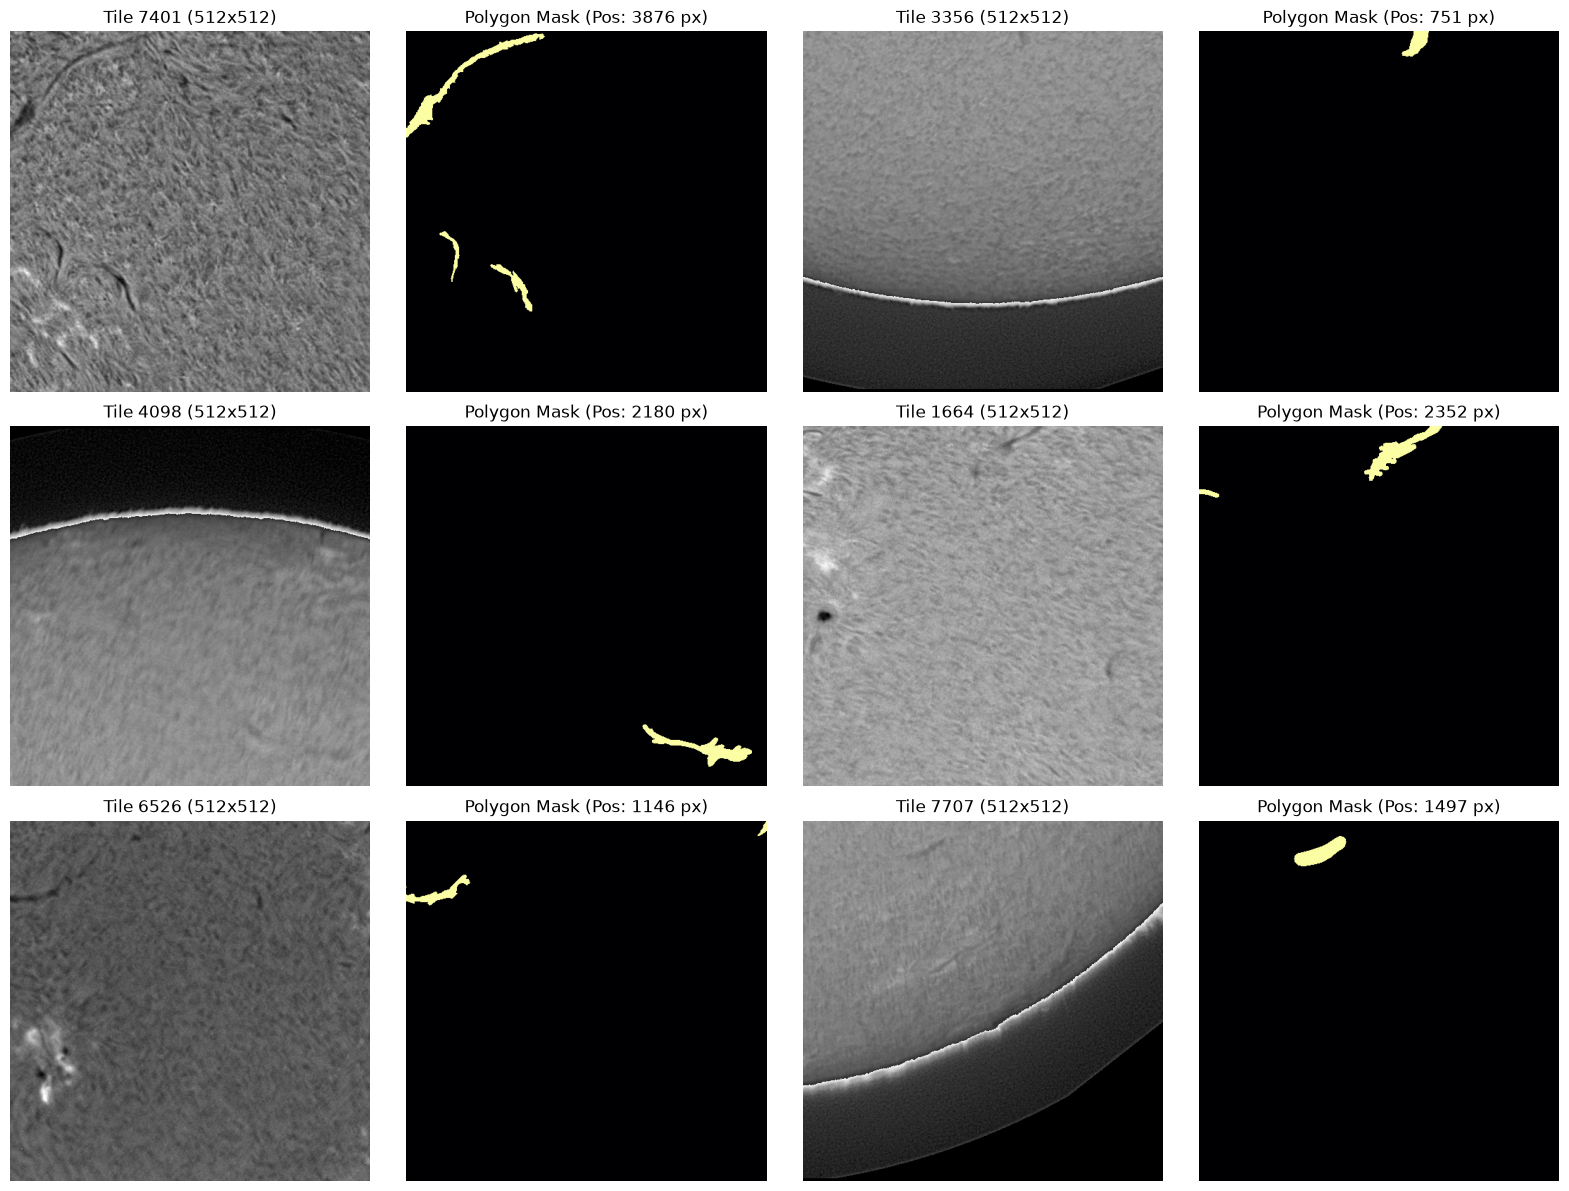

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
sample_indices = [random.randint(0, len(train_dataset)-1) for _ in range(6)]

for i, s_idx in enumerate(sample_indices):
    img_t, mask_t = train_dataset[s_idx]
    row = i // 2
    col_img = (i % 2) * 2
    col_mask = col_img + 1
    
    axes[row, col_img].imshow(img_t[0].numpy(), cmap='gray')
    axes[row, col_img].set_title(f"Tile {s_idx} ({config.TILE_SIZE}x{config.TILE_SIZE})")
    axes[row, col_img].axis('off')
    
    axes[row, col_mask].imshow(mask_t[0].numpy(), cmap='inferno')
    axes[row, col_mask].set_title(f"Polygon Mask (Pos: {mask_t.sum().item():.0f} px)")
    axes[row, col_mask].axis('off')

plt.tight_layout()
plt.show()


## 5. Pretrained U-Net Architecture & Recall-Biased BCE-Tversky Loss

$$\text{Tversky}(\hat{y}, y) = \frac{\text{TP} + \epsilon}{\text{TP} + \alpha \text{FP} + \beta \text{FN} + \epsilon}$$

With $\alpha=0.3$ and $\beta=0.7$, False Negatives receive $>2.3\times$ higher penalty than False Positives, directly targeting the low Recognition Quality ($RQ$) of missed filaments.

In [6]:
def build_model(encoder_name="resnet34", encoder_weights="imagenet"):
    # Output raw single-channel logits (activation=None) for mixed precision stability
    model = smp.Unet(
        encoder_name=encoder_name,
        encoder_weights=encoder_weights,
        in_channels=3,
        classes=1,
        activation=None
    )
    return model

class BCETverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, bce_weight=0.5, smooth=1e-6):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.bce_weight = bce_weight
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, target):
        bce_loss = self.bce(logits, target)
        
        probs = torch.sigmoid(logits)
        pred_flat = probs.view(probs.size(0), -1)
        target_flat = target.view(target.size(0), -1)
        
        tp = (pred_flat * target_flat).sum(dim=1)
        fp = (pred_flat * (1.0 - target_flat)).sum(dim=1)
        fn = ((1.0 - pred_flat) * target_flat).sum(dim=1)
        
        tversky = (tp + self.smooth) / (tp + self.alpha * fp + self.beta * fn + self.smooth)
        tversky_loss = (1.0 - tversky).mean()
        
        return self.bce_weight * bce_loss + (1.0 - self.bce_weight) * tversky_loss

def compute_dice(logits, targets, threshold=0.5):
    with torch.no_grad():
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        inter = (preds * targets).sum().item()
        tot = preds.sum().item() + targets.sum().item()
        return (2.0 * inter) / (tot + 1e-8) if tot > 0 else 1.0

def compute_iou(logits, targets, threshold=0.5):
    with torch.no_grad():
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        inter = (preds * targets).sum().item()
        union = preds.sum().item() + targets.sum().item() - inter
        return inter / (union + 1e-8) if union > 0 else 1.0


## 6. Training Pipeline (CUDA Mixed Precision & Cosine LR Scheduling)

In [7]:
def train_v5_pipeline(model, train_loader, val_loader, epochs=20, lr=1e-4, save_path="best_filament_unet_v5.pt"):
    criterion = BCETverskyLoss(alpha=config.TVERSKY_ALPHA, beta=config.TVERSKY_BETA, bce_weight=config.BCE_WEIGHT)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=config.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = GradScaler('cuda')
    
    history = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_iou': [], 'lr': []}
    best_val_dice = 0.0
    
    for epoch in range(1, epochs + 1):
        model.train()
        running_train_loss = 0.0
        
        pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{epochs:02d} [Train]")
        for imgs, masks in pbar:
            imgs = imgs.to(config.DEVICE)
            masks = masks.to(config.DEVICE)
            
            optimizer.zero_grad()
            with autocast('cuda'):
                logits = model(imgs)
                loss = criterion(logits, masks)
                
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            
            running_train_loss += loss.item() * imgs.size(0)
            pbar.set_postfix({'loss': f"{loss.item():.4f}"})
            
        train_loss = running_train_loss / len(train_loader.dataset)
        
        # Validation Phase
        model.eval()
        running_val_loss = 0.0
        running_val_dice = 0.0
        running_val_iou = 0.0
        
        with torch.no_grad():
            for imgs, masks in tqdm(val_loader, desc=f"Epoch {epoch:02d}/{epochs:02d} [Val]"):
                imgs = imgs.to(config.DEVICE)
                masks = masks.to(config.DEVICE)
                
                with autocast('cuda'):
                    logits = model(imgs)
                    loss = criterion(logits, masks)
                    
                running_val_loss += loss.item() * imgs.size(0)
                running_val_dice += compute_dice(logits, masks) * imgs.size(0)
                running_val_iou += compute_iou(logits, masks) * imgs.size(0)
                
        val_loss = running_val_loss / len(val_loader.dataset)
        val_dice = running_val_dice / len(val_loader.dataset)
        val_iou = running_val_iou / len(val_loader.dataset)
        current_lr = optimizer.param_groups[0]['lr']
        scheduler.step()
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice)
        history['val_iou'].append(val_iou)
        history['lr'].append(current_lr)
        
        # Save Best Checkpoint based on Validation Mask Dice
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            torch.save(model.state_dict(), save_path)
            saved_tag = f" --> [BEST MODEL SAVED: Dice={val_dice:.4f}]"
        else:
            saved_tag = ""
            
        print(f"Epoch [{epoch:02d}/{epochs:02d}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f} | Val IoU: {val_iou:.4f} | LR: {current_lr:.6f}{saved_tag}")
        
        # Free GPU and CPU memory between epochs to prevent OOM
        del imgs, masks, logits, loss
        torch.cuda.empty_cache()
        gc.collect()
        
    print(f"\nTraining Complete! Best Checkpoint Saved to: {save_path} (Val Dice: {best_val_dice:.4f})")
    return history

# Instantiate and train model
model_v5 = build_model(config.ENCODER_NAME, config.ENCODER_WEIGHTS).to(config.DEVICE)
history_v5 = train_v5_pipeline(model_v5, train_loader, val_loader, epochs=config.NUM_EPOCHS, lr=config.LEARNING_RATE, save_path=config.MODEL_SAVE_PATH)


Epoch 01/20 [Val]: 100%|██████████| 541/541 [00:48<00:00, 11.06it/s]


Epoch [01/20] | Train Loss: 0.4262 | Val Loss: 0.3989 | Val Dice: 0.5144 | Val IoU: 0.3813 | LR: 0.000100 --> [BEST MODEL SAVED: Dice=0.5144]


Epoch 02/20 [Val]: 100%|██████████| 541/541 [00:48<00:00, 11.18it/s]


Epoch [02/20] | Train Loss: 0.2311 | Val Loss: 0.3832 | Val Dice: 0.5111 | Val IoU: 0.3760 | LR: 0.000099


Epoch 03/20 [Val]: 100%|██████████| 541/541 [00:48<00:00, 11.15it/s]


Epoch [03/20] | Train Loss: 0.2154 | Val Loss: 0.3818 | Val Dice: 0.5133 | Val IoU: 0.3793 | LR: 0.000098


... (30 outputs left out)

Epoch 19/20 [Val]: 100%|██████████| 541/541 [00:48<00:00, 11.20it/s]


Epoch [19/20] | Train Loss: 0.1792 | Val Loss: 0.3726 | Val Dice: 0.5452 | Val IoU: 0.4136 | LR: 0.000003


Epoch 20/20 [Val]: 100%|██████████| 541/541 [00:48<00:00, 11.17it/s]

Epoch [20/20] | Train Loss: 0.1779 | Val Loss: 0.3725 | Val Dice: 0.5499 | Val IoU: 0.4186 | LR: 0.000002

Training Complete! Best Checkpoint Saved to: best_filament_unet_v5.pt (Val Dice: 0.5738)


## 7. Performance & Convergence Curves

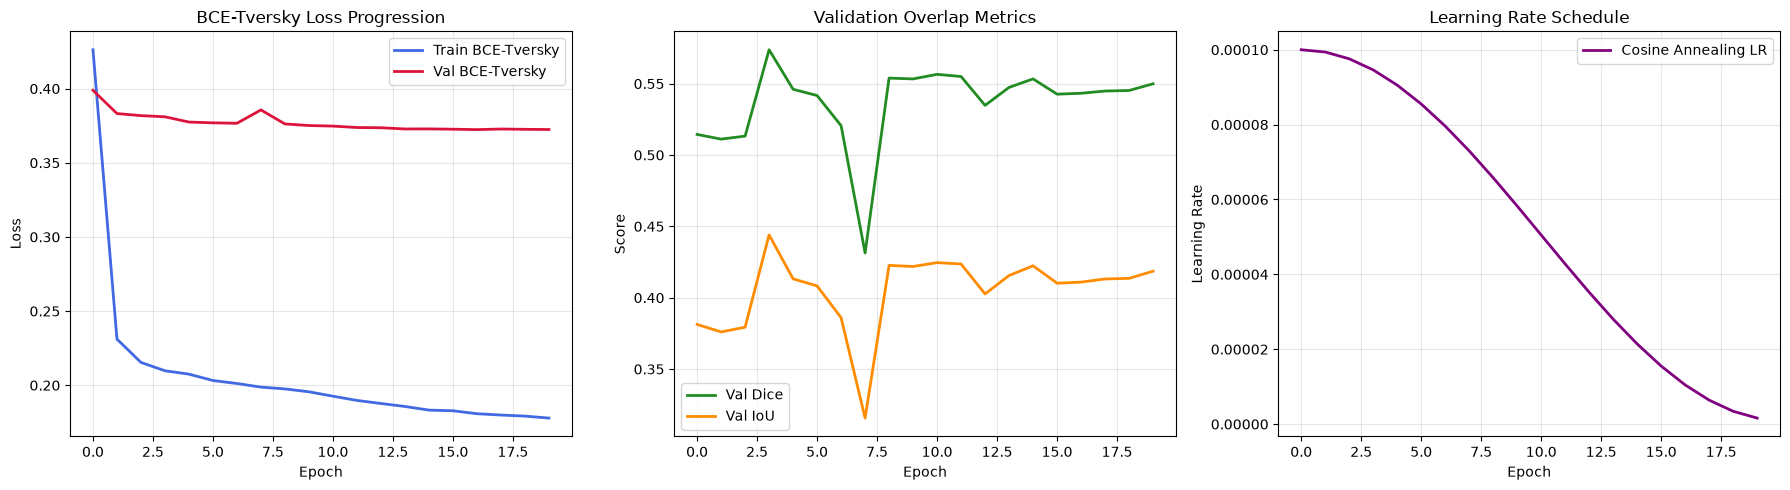

In [8]:
if 'history_v5' in globals() and history_v5:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Loss
    axes[0].plot(history_v5['train_loss'], label='Train BCE-Tversky', color='royalblue', lw=2)
    axes[0].plot(history_v5['val_loss'], label='Val BCE-Tversky', color='crimson', lw=2)
    axes[0].set_title("BCE-Tversky Loss Progression")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # 2. Dice & IoU
    axes[1].plot(history_v5['val_dice'], label='Val Dice', color='forestgreen', lw=2)
    axes[1].plot(history_v5['val_iou'], label='Val IoU', color='darkorange', lw=2)
    axes[1].set_title("Validation Overlap Metrics")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Score")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # 3. Learning Rate
    axes[2].plot(history_v5['lr'], label='Cosine Annealing LR', color='purple', lw=2)
    axes[2].set_title("Learning Rate Schedule")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Learning Rate")
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    print("Training cell was skipped -- using existing saved checkpoint (best_filament_unet_v5.pt) directly.")


## 8. Overlapping Tiled Stitching & Watershed Instance Separation

1. **`predict_full_image`**: Runs inference across overlapping $512\times 512$ tiles with stride $384$, accumulating probabilities with a normalized weight grid to eliminate tile edge artifacts.
2. **`watershed_instances`**: Computes Euclidean Distance Transform (EDT) and marks local maxima to split touching filament bottlenecks without fragmenting single bodies.

In [9]:
# Load Champion Checkpoint
eval_model = build_model(config.ENCODER_NAME, encoder_weights=None).to(config.DEVICE)
if os.path.exists(config.MODEL_SAVE_PATH):
    eval_model.load_state_dict(torch.load(config.MODEL_SAVE_PATH, map_location=config.DEVICE))
    print(f"Loaded Trained Model from: {config.MODEL_SAVE_PATH}")
eval_model.eval()

def predict_full_image(model, image_path, device, full_res=2048, tile_size=512, stride=384):
    image = Image.open(image_path).convert("L").resize((full_res, full_res), Image.BILINEAR)
    prob_sum = np.zeros((full_res, full_res), dtype=np.float32)
    weight = np.zeros((full_res, full_res), dtype=np.float32)
    
    coords = FilamentTileDataset._build_tile_grid(full_res, tile_size, stride)
    model.eval()
    with torch.no_grad():
        for x, y in coords:
            tile = image.crop((x, y, x + tile_size, y + tile_size))
            tile_t = TF.to_tensor(tile).repeat(3, 1, 1).unsqueeze(0).to(device)
            with autocast('cuda'):
                logit = model(tile_t)
                pred = torch.sigmoid(logit)[0, 0].cpu().numpy()
                
            prob_sum[y:y + tile_size, x:x + tile_size] += pred
            weight[y:y + tile_size, x:x + tile_size] += 1.0
            
    return prob_sum / np.maximum(weight, 1e-6)

def postprocess(prob_map, threshold=0.45, min_area=500):
    """
    Clean 8-connected component postprocessing to extract contiguous filament instances
    without over-segmenting/shattering single filaments.
    """
    binary_mask = (prob_map > threshold).astype(np.uint8)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask, connectivity=8)
    
    clean_instances = []
    clean_full_mask = np.zeros_like(binary_mask)
    
    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            inst_m = (labels == i).astype(np.uint8)
            clean_instances.append(inst_m)
            clean_full_mask[labels == i] = 1
            
    return clean_full_mask, clean_instances


Loaded Trained Model from: best_filament_unet_v5.pt


## 9. Qualitative Validation Comparison: Full $2048\times 2048$ Solar Disk Predictions

GPU memory after cleanup: 0.10 GB allocated | 0.26 GB reserved
Evaluating Full-Disk Stitched Prediction on Validation Image: 20160401170314Mh.jpeg


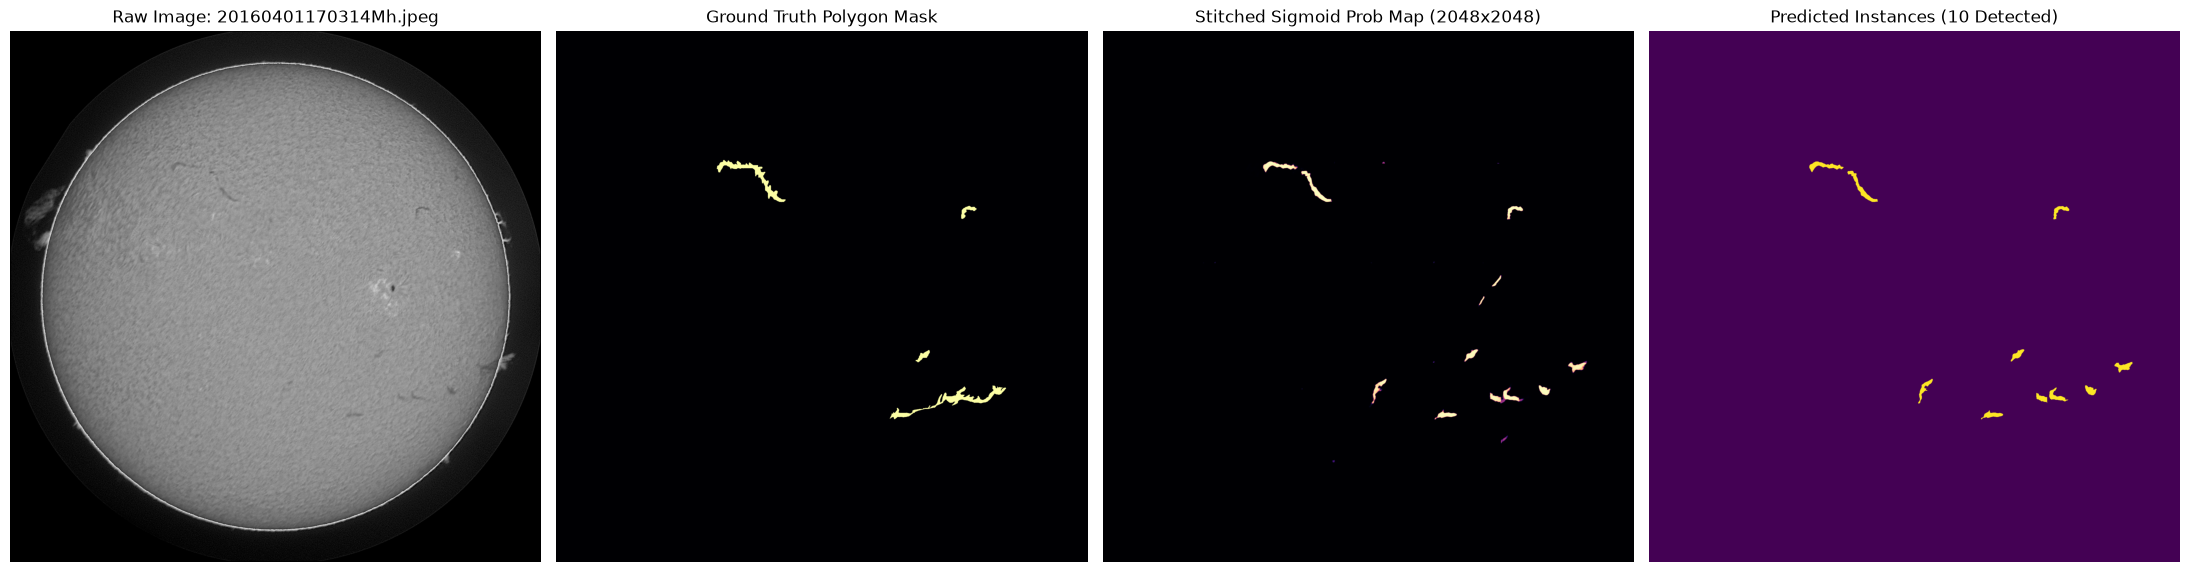

In [10]:
import gc

# Free training model from GPU memory
try:
    del model_v5
except NameError:
    pass
torch.cuda.empty_cache()
gc.collect()
print(f"GPU memory after cleanup: {torch.cuda.memory_allocated()/1e9:.2f} GB allocated | {torch.cuda.memory_reserved()/1e9:.2f} GB reserved")

sample_val_id   = val_img_ids[0]
sample_fname    = images_dict[sample_val_id]['file_name']
sample_img_path = config.TRAIN_IMG_DIR / sample_fname

print(f"Evaluating Full-Disk Stitched Prediction on Validation Image: {sample_fname}")
full_prob = predict_full_image(eval_model, sample_img_path, config.DEVICE,
                                config.FULL_RES, config.TILE_SIZE, config.STRIDE)

clean_mask, instances = postprocess(full_prob,
                                     threshold=config.PROB_THRESHOLD,
                                     min_area=config.MIN_AREA_THRESHOLD)

_, gt_full_mask = val_dataset._load_full_image_and_mask(sample_val_id)

fig, axes = plt.subplots(1, 4, figsize=(22, 6))

axes[0].imshow(Image.open(sample_img_path).convert('L'), cmap='gray')
axes[0].set_title(f"Raw Image: {sample_fname}")
axes[0].axis('off')

axes[1].imshow(np.array(gt_full_mask), cmap='inferno')
axes[1].set_title("Ground Truth Polygon Mask")
axes[1].axis('off')

axes[2].imshow(full_prob, cmap='magma', vmin=0, vmax=1)
axes[2].set_title("Stitched Sigmoid Prob Map (2048x2048)")
axes[2].axis('off')

axes[3].imshow(clean_mask, cmap='viridis')
axes[3].set_title(f"Predicted Instances ({len(instances)} Detected)")
axes[3].axis('off')

plt.tight_layout()
plt.show()


## 10. Kaggle Submission Generation (`submission_v5.csv`)

Generates 1-indexed column-major Run-Length Encodings (RLE) for all 180 test solar images.

In [12]:
# ── Submission Generation (pycocotools RLE Counts format) ──────────────────
import csv
import pycocotools.mask as coco_mask_util

SUBMISSION_H = 2048
SUBMISSION_W = 2048

def encode_mask_to_rle_counts(binary_mask_2d):
    h, w = binary_mask_2d.shape
    if (h, w) != (SUBMISSION_H, SUBMISSION_W):
        binary_mask_2d = cv2.resize(
            binary_mask_2d.astype(np.uint8),
            (SUBMISSION_W, SUBMISSION_H),
            interpolation=cv2.INTER_NEAREST,
        )
    mask_f = np.asfortranarray(binary_mask_2d.astype(np.uint8))
    rle = coco_mask_util.encode(mask_f)
    return rle["counts"].decode("ascii")

test_images = sorted(
    list(config.TEST_IMG_DIR.glob("*.png")) +
    list(config.TEST_IMG_DIR.glob("*.jpeg")) +
    list(config.TEST_IMG_DIR.glob("*.jpg"))
)

print(f"Running High-Resolution Tiled Inference on {len(test_images)} Test Images...")

submission_rows = []
eval_model.eval()

for img_path in tqdm(test_images, desc="Test Inference"):
    prob_map = predict_full_image(
        eval_model, img_path, config.DEVICE,
        config.FULL_RES, config.TILE_SIZE, config.STRIDE,
    )
    _, instances = postprocess(
        prob_map,
        threshold=config.PROB_THRESHOLD,
        min_area=config.MIN_AREA_THRESHOLD,
    )
    base_name = img_path.stem  # e.g. '20150125172714Mh'

    if instances:
        for f_idx, inst_m in enumerate(instances, 1):
            submission_rows.append({
                "filament_id": f"{base_name}_{f_idx}",
                "segmentation_rle": encode_mask_to_rle_counts(inst_m),
            })
    else:
        empty_mask = np.zeros((SUBMISSION_H, SUBMISSION_W), dtype=np.uint8)
        submission_rows.append({
            "filament_id": f"{base_name}_1",
            "segmentation_rle": encode_mask_to_rle_counts(empty_mask),
        })

submission_df = pd.DataFrame(submission_rows, columns=["filament_id", "segmentation_rle"])
# Write manually so the RLE string is never modified by pandas escaping
with open(config.SUBMISSION_PATH, 'w', newline='') as f:
    f.write("filament_id,segmentation_rle\n")
    for row in submission_rows:
        f.write(f"{row['filament_id']},{row['segmentation_rle']}\n")

print(f"\nSubmission saved to: {config.SUBMISSION_PATH}")
print(f"Total rows: {len(submission_df)} (Avg: {len(submission_df)/len(test_images):.1f} instances/image)")
print(submission_df.head(10).to_string())


Running High-Resolution Tiled Inference on 180 Test Images...


Test Inference: 100%|██████████| 180/180 [01:42<00:00,  1.76it/s]


Submission saved to: submission_v5.csv
Total rows: 1519 (Avg: 8.4 instances/image)
          filament_id                                                                                                                                                                                                                                                                                                                                                                                                         segmentation_rle
0  20110120105534Ch_1                                                                                                                                                                                                  l_Vi25ko11O101O1N10000O2O4MO00O105K01N1O00010O11O01O00001N1O100O1O001O010O01O0100O010000O3N0O1O1O1O1N2O101N10O2N2N4L1N100O1O2N1001O01000O10O10O10000O11OO010O001O10O010O001O00001O00001O0O1O10000O11OO2O001O000O2OW^]P1
1  20110120105534Ch_2                                 

## 11. Official Competition Panoptic Quality (PQ) Metric Self-Evaluation

$$\text{PQ} = \text{SQ} \times \text{RQ} = \frac{\sum_{(p, g) \in TP} \text{IoU}(p, g)}{|TP|} \times \frac{|TP|}{|TP| + \frac{1}{2}|FP| + \frac{1}{2}|FN|}$$

In [ ]:
def compute_pq_metric(gt_instances_by_img, pred_instances_by_img, iou_threshold=0.5):
    total_tp = 0
    total_fp = 0
    total_fn = 0
    sum_iou = 0.0
    
    all_imgs = set(gt_instances_by_img.keys()).union(pred_instances_by_img.keys())
    
    for img_key in all_imgs:
        gts = gt_instances_by_img.get(img_key, [])
        preds = pred_instances_by_img.get(img_key, [])
        
        if len(gts) == 0 and len(preds) == 0:
            continue
        if len(gts) == 0:
            total_fp += len(preds)
            continue
        if len(preds) == 0:
            total_fn += len(gts)
            continue
            
        iou_matrix = np.zeros((len(preds), len(gts)))
        for p_i, p_m in enumerate(preds):
            for g_i, g_m in enumerate(gts):
                inter = np.logical_and(p_m, g_m).sum()
                union = np.logical_or(p_m, g_m).sum()
                iou_matrix[p_i, g_i] = inter / (union + 1e-8)
                
        matched_gts = set()
        matched_preds = set()
        matches = []
        
        for p_i in range(len(preds)):
            for g_i in range(len(gts)):
                if iou_matrix[p_i, g_i] >= iou_threshold:
                    matches.append((iou_matrix[p_i, g_i], p_i, g_i))
                    
        matches.sort(key=lambda x: x[0], reverse=True)
        for iou_val, p_i, g_i in matches:
            if p_i not in matched_preds and g_i not in matched_gts:
                matched_preds.add(p_i)
                matched_gts.add(g_i)
                total_tp += 1
                sum_iou += iou_val
                
        total_fp += len(preds) - len(matched_preds)
        total_fn += len(gts) - len(matched_gts)
        
    sq = sum_iou / total_tp if total_tp > 0 else 0.0
    rq = total_tp / (total_tp + 0.5 * total_fp + 0.5 * total_fn) if (total_tp + total_fp + total_fn) > 0 else 0.0
    pq = sq * rq
    
    return {
        "PQ (Panoptic Quality)": pq,
        "SQ (Segmentation Quality)": sq,
        "RQ (Recognition Quality)": rq,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn
    }

# Run PQ Evaluation on Validation Subset
eval_val_subset = val_img_ids[:25]
val_gt_dict = {}
val_pred_dict = {}

print(f"Evaluating Panoptic Quality on {len(eval_val_subset)} Validation Images...")
for v_id in tqdm(eval_val_subset, desc="PQ Evaluation"):
    fname = images_dict[v_id]['file_name']
    img_path = config.TRAIN_IMG_DIR / fname
    orig_w, orig_h = images_dict[v_id]['width'], images_dict[v_id]['height']
    
    # Extract ground truth instances
    gts = []
    for a in annotations_by_image.get(v_id, []):
        m = np.zeros((orig_h, orig_w), dtype=np.uint8)
        for poly in a.get('segmentation', []):
            pts = np.array(poly, dtype=np.int32).reshape((-1, 2))
            cv2.fillPoly(m, [pts], 1)
        gts.append(m)
    val_gt_dict[fname] = gts
    
    # Stitched prediction
    prob_map = predict_full_image(eval_model, img_path, config.DEVICE, config.FULL_RES, config.TILE_SIZE, config.STRIDE)
    prob_native = cv2.resize(prob_map, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
    scale_factor = (orig_w / config.FULL_RES) * (orig_h / config.FULL_RES)
    scaled_min_area = int(config.MIN_AREA_THRESHOLD * scale_factor)
    _, preds = postprocess(prob_native, threshold=config.PROB_THRESHOLD, min_area=scaled_min_area)
    val_pred_dict[fname] = preds

pq_summary = compute_pq_metric(val_gt_dict, val_pred_dict, iou_threshold=0.5)

print("\n" + "=" * 60)
print("VAL SET PANOPTIC QUALITY (PQ) SUMMARY")
print("=" * 60)
for k, v in pq_summary.items():
    if isinstance(v, float):
        print(f"{k:30s}: {v:.4f}")
    else:
        print(f"{k:30s}: {v}")
print("=" * 60)
